<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/03_modeles_entrainement_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Road Anomaly Detection — 03. Modèles et entraînement

**Projet Deep Learning | CRISP-DM — Phase 4 : Modélisation**

Ce notebook présente les approches de détection d’anomalies routières, justifie leur choix, puis montre l’entraînement et les **courbes d’apprentissage**.

| # | Modèle | Famille | Supervision |
|---|---|---|---|
| 1 | U-Net simple (*from scratch*, encodeur ResNet18) | CNN de segmentation | Supervisée (masques) |
| 2 | U-Net ResNet34 pré-entraîné ImageNet | Segmentation + *transfer learning* | Supervisée |
| 3 | DeepLabV3 + ResNet18 pré-entraîné ImageNet | Segmentation multi-échelle | Supervisée |
| 4 | Autoencodeur convolutionnel (pixels) | Reconstruction | Reconstruction guidée par les masques* |
| 5 | Autoencodeur sur caractéristiques ResNet34 gelées | Reconstruction de *features* | Reconstruction guidée par les masques* |
| A | Ablation : U-Net ResNet34 **sans** pré-entraînement | Contrôle expérimental | Supervisée |
| 6 | Mask R-CNN ResNet50-FPN | Segmentation d’instances | Supervisée (objets) |

\* Les autoencodeurs apprennent à reconstruire **les zones normales** ; les masques sont utilisés pour exclure les anomalies de leur perte. Ce n’est donc pas une méthode entièrement non supervisée.

**Protocole :** découpage fixé dans le notebook 02 (**42/9/9**, dont **33/5/8** images annotées en instances). Sélection des meilleurs modèles sur validation, puis évaluation finale sur test.

## 1. Justification des choix de modèles

**Pourquoi la segmentation sémantique ?** Les annotations sont au niveau **pixel** et l’objectif est de **localiser** les objets dangereux : une sortie pixel par pixel (masque) est la formulation naturelle, plutôt qu’une simple classification d’image.

1. **U-Net from scratch** (Ronneberger et al., 2015) — encodeur-décodeur avec *skip connections* : l’encodeur capte le contexte, le décodeur restitue la résolution et les connexions préservent les contours fins. C’est une **baseline CNN** sans connaissance préalable. Dans ce notebook, son encodeur est **ResNet18 non pré-entraîné**.
2. **U-Net ResNet34 pré-entraîné** — avec seulement 60 images, apprendre des filtres génériques (bords, textures, formes) est difficile ; un encodeur pré-entraîné sur **ImageNet** fournit déjà ces représentations : c’est le **transfer learning**.
3. **DeepLabV3 + ResNet18** — le module ASPP (*atrous spatial pyramid pooling*) agrège le contexte à plusieurs échelles, utile pour des anomalies petites ou grandes. **Ici l’encodeur est ResNet18 ImageNet**, et non MobileNetV3 COCO comme dans l’autre notebook.
4. **Autoencodeur (pixels)** — un réseau entraîné à reconstruire les **régions normales** peut produire une erreur élevée sur l’inattendu. L’erreur de reconstruction devient une **carte d’anomalie** ; cette approche complète la segmentation supervisée.
5. **Autoencodeur sur caractéristiques** — la reconstruction dans l’espace pixel est sensible aux couleurs. Reconstruire les **caractéristiques profondes** d’un ResNet34 gelé vise à mieux représenter les structures visuelles.
6. **Mask R-CNN** — détecte chaque obstacle individuellement en prédisant **une boîte, un label et un masque** par objet, contrairement aux réseaux de segmentation sémantique.

**Ablation :** pour isoler l’effet du pré-entraînement, on entraîne exactement la même architecture U-Net ResNet34 avec des poids aléatoires.

**Question du projet :** quelle famille de modèles est la plus appropriée à la localisation des anomalies, et que gagne-t-on avec le *transfer learning* sur un petit dataset ?

## 2. Configuration d’entraînement

| Élément | Choix dans **ce notebook** | Raison |
|---|---|---|
| Données | 60 images, **42 train / 9 validation / 9 test** | Séparer apprentissage, choix des réglages et évaluation finale |
| Résolution | **256 × 256**, `ImageOps.pad` | Entrées homogènes, sans étirer les images ; ajustement par bandes |
| Augmentation | Flip horizontal, luminosité et contraste (sur **train** seulement) | Diversifier les exemples sans modifier les masques de validation/test |
| Perte (segmentation) | **BCE + Dice loss** | Gérer la classification binaire des pixels et leur recouvrement |
| Perte (autoencodeurs) | Reconstruction sur les **zones normales uniquement** | Apprendre à reconstruire le fond sans récompenser la copie des anomalies |
| Optimiseur | **AdamW**, `weight_decay=1e-4` | Optimisation stable avec régularisation |
| Learning rate | **1e-3** scratch ; **1e-3 et 3e-4** sur ResNet34 pré-entraîné ; **3e-4** DeepLabV3 ; **1e-3** autoencodeurs ; **1e-4** Mask R-CNN | Tester des vitesses d’apprentissage adaptées aux tâches |
| Lots | **4** (sémantique et autoencodeurs), **2** (Mask R-CNN train) | Compromis mémoire GPU et stabilité des gradients |
| Époques maximum | **12** sémantique ; **25/20** autoencodeurs ; **8** Mask R-CNN | Budget expérimental, sans prétendre que ces valeurs sont optimales |
| Sélection | **IoU validation** (sémantique), **AP validation** (autoencodeurs), **IoU union validation** (Mask R-CNN) | Éviter de sélectionner un modèle sur le test |
| Arrêt anticipé | Patience **4**, **6**, **3**, respectivement | Limiter le surapprentissage |
| Binarisation | Seuil **0,5** segmentation ; seuil autoencodeurs choisi sur validation | Comparaison reproductible sans exploiter les labels du test pour régler le seuil |

### Pourquoi tester plusieurs hyperparamètres ?

Un **paramètre** (poids du réseau) est appris pendant l’entraînement. Un **hyperparamètre** (*learning rate*, taille de lot, patience…) est fixé avant l’apprentissage.

- **Learning rate trop grand :** optimisation instable ; **trop petit :** convergence lente.
- **Batch size faible :** moins de mémoire, mais gradients plus variables.
- **Weight decay :** aide à réduire le surapprentissage ; il ne remplace pas la validation.
- **Early stopping :** conserve le checkpoint de la **meilleure époque de validation**, pas forcément la dernière.
- **Ablation scratch/pré-entraîné :** teste l’apport des poids ImageNet à architecture identique.

**Expérience effectivement réalisée :** deux learning rates sont comparés pour **U-Net ResNet34 pré-entraîné**. Ce n’est pas une recherche exhaustive : avec 9 images de validation, les scores peuvent fluctuer. Il faut conserver **le même split** et ne jamais choisir sur le test.

> **Différence avec le notebook de référence :** ici, pas de *random crop*, de BCE pondérée ni de scheduler cosinus ; l’encodeur et le décodeur utilisent le même LR dans la boucle d’entraînement actuelle. Ces méthodes peuvent être étudiées ultérieurement mais ne sont pas revendiquées comme déjà utilisées.

### 2.1. Environnement et reproductibilité

Exécuter dans l’ordre sur **Google Colab avec GPU**. Les poids pré-entraînés sont téléchargés au premier lancement. Les checkpoints et historiques sont conservés dans Google Drive.

In [ ]:
%pip -q install "segmentation-models-pytorch>=0.4,<0.6"

In [ ]:
import os, random, copy, gc
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import segmentation_models_pytorch as smp
from google.colab import drive

drive.mount('/content/drive')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG_SIZE = (256, 256)
SPLIT_CSV = Path('/content/drive/MyDrive/deep learning P/split_manifest.csv')
OUT = Path('/content/drive/MyDrive/deep learning P/RoadAnomaly_final_models')
OUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| Fichier split:', SPLIT_CSV)
assert SPLIT_CSV.exists(), 'Exécuter la section 3.2 du notebook 02 pour créer split_manifest.csv.'
if DEVICE.type == 'cpu': print('⚠ Activez un GPU Colab avant les entraînements.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Fichier split: /content/drive/MyDrive/deep learning P/split_manifest.csv


### 2.2. Charger le découpage préparé dans le notebook 02

On recharge `split_manifest.csv` au lieu de tirer un nouveau découpage. Les **46 images avec annotations d’instances** sont un sous-ensemble des 60 images.

In [ ]:
split = pd.read_csv(SPLIT_CSV)
required = {'image','mask','instance_mask','split'}
assert required.issubset(split.columns), f'Colonnes manquantes: {required - set(split.columns)}'
assert split['split'].value_counts().to_dict() == {'train':42,'validation':9,'test':9}
assert split['image'].is_unique, 'Image présente plusieurs fois dans le manifeste.'
assert all(Path(p).exists() for p in split['image'])
assert all(Path(p).exists() for p in split['mask'])
split['instance_mask'] = split['instance_mask'].replace('', np.nan)
for p in split['instance_mask'].dropna(): assert Path(p).exists(), p
assert split['instance_mask'].notna().sum() == 46
train_df = split.query("split == 'train'").reset_index(drop=True)
val_df = split.query("split == 'validation'").reset_index(drop=True)
test_df = split.query("split == 'test'").reset_index(drop=True)
print('Sémantique:', len(train_df),len(val_df),len(test_df))
print('Instances:', *(x['instance_mask'].notna().sum() for x in [train_df,val_df,test_df]))

Sémantique: 42 9 9
Instances: 33 5 8


### 2.3. Prétraitement et augmentation

Les images RGB sont mises au format **256 × 256** à l’aide d’un redimensionnement avec **bandes de remplissage** (`ImageOps.pad`). Les masques sont transformés avec interpolation *nearest-neighbor* afin de préserver leurs labels. Les masques sémantiques sont binarisés (**2 → 1**), tandis que les IDs d’instances sont conservés.

Les augmentations sont appliquées **conjointement à l’image et à son masque**, uniquement sur train. Les modèles sémantiques reçoivent une normalisation ImageNet ; Mask R-CNN reçoit des images `[0,1]` car `torchvision` applique sa propre normalisation.

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def load_image(path):
    im = Image.open(path).convert('RGB')
    im = ImageOps.pad(im, IMG_SIZE, method=Image.Resampling.BILINEAR, color=(0,0,0))
    return np.asarray(im, dtype=np.float32)/255.0

def load_mask(path, binary=True):
    im = Image.open(path)
    im = ImageOps.pad(im, IMG_SIZE, method=Image.Resampling.NEAREST, color=0)
    arr = np.asarray(im)
    return (arr == 2).astype(np.float32) if binary else arr

def augment(image, mask):
    if np.random.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=-1).copy() # mask 2D or [N,H,W]
    brightness = np.random.uniform(0.8,1.2)
    image = np.clip(image*brightness, 0,1)
    contrast = np.random.uniform(0.8,1.2)
    mu = image.mean(axis=(0,1), keepdims=True)
    return np.clip((image-mu)*contrast+mu,0,1).astype(np.float32), mask

class SemanticDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame=frame.reset_index(drop=True); self.training=training
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        im=load_image(r['image']); m=load_mask(r['mask'])
        if self.training: im,m=augment(im,m)
        im=(im-MEAN)/STD
        return (torch.from_numpy(np.ascontiguousarray(im.transpose(2,0,1))).float(),
                torch.from_numpy(np.ascontiguousarray(m[None])).float())

def semantic_loaders(batch=4):
    return (DataLoader(SemanticDataset(train_df,True),batch_size=batch,shuffle=True,num_workers=0),
            DataLoader(SemanticDataset(val_df),batch_size=batch,shuffle=False,num_workers=0),
            DataLoader(SemanticDataset(test_df),batch_size=batch,shuffle=False,num_workers=0))

train_loader,val_loader,test_loader=semantic_loaders(4)
print('DataLoaders sémantiques :',len(train_loader.dataset),len(val_loader.dataset),len(test_loader.dataset))

DataLoaders sémantiques : 42 9 9


### 2.4. Architectures, pertes et métriques

La segmentation sémantique est évaluée avec **IoU, Dice, précision et rappel** (moyennes des scores par image). La fonction de perte combine **BCE + Dice**. Le seuil est fixé à **0,5** pour ces modèles.

Les métriques des autoencodeurs et de Mask R-CNN seront **interprétées séparément**, car elles n’évaluent pas exactement la même tâche.

In [ ]:
def make_semantic_model(name):
    if name=='unet_simple':
        return smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=3,classes=1)
    if name=='unet_resnet34_scratch':
        return smp.Unet(encoder_name='resnet34',encoder_weights=None,in_channels=3,classes=1)
    if name=='unet_resnet34_pretrained':
        return smp.Unet(encoder_name='resnet34',encoder_weights='imagenet',in_channels=3,classes=1)
    if name=='deeplabv3_resnet18':
        return smp.DeepLabV3(encoder_name='resnet18',encoder_weights='imagenet',in_channels=3,classes=1)
    raise ValueError(name)

def seg_loss(logits,mask):
    bce=nn.functional.binary_cross_entropy_with_logits(logits,mask)
    probs=torch.sigmoid(logits)
    intersection=(probs*mask).sum(dim=(1,2,3))
    dice=(2*intersection+1e-6)/(probs.sum(dim=(1,2,3))+mask.sum(dim=(1,2,3))+1e-6)
    return bce+(1-dice.mean())

@torch.no_grad()
def semantic_scores(model,loader,threshold=0.5):
    model.eval(); rows=[]
    for images,masks in loader:
        logits=model(images.to(DEVICE))
        preds=(torch.sigmoid(logits)>threshold).cpu().numpy().astype(bool)
        true=masks.numpy().astype(bool)
        for p,t in zip(preds,true):
            tp=np.logical_and(p,t).sum(); fp=np.logical_and(p,~t).sum(); fn=np.logical_and(~p,t).sum()
            rows.append({'IoU':(tp+1e-7)/(tp+fp+fn+1e-7),
                         'Dice':(2*tp+1e-7)/(2*tp+fp+fn+1e-7),
                         'Precision':(tp+1e-7)/(tp+fp+1e-7),
                         'Recall':(tp+1e-7)/(tp+fn+1e-7)})
    return pd.DataFrame(rows).mean().to_dict()

def fit_semantic(name,lr=1e-3,epochs=12,patience=4,checkpoint=None):
    path=OUT/(checkpoint or f'{name}.pt')
    model=make_semantic_model(name).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    best=-1; bad=0; log=[]
    for epoch in range(1,epochs+1):
        model.train(); losses=[]
        for x,y in train_loader:
            x=x.to(DEVICE); y=y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss=seg_loss(model(x),y); loss.backward()
            optimizer.step(); losses.append(loss.item())
        val=semantic_scores(model,val_loader)
        log.append({'epoch':epoch,'train_loss':np.mean(losses),**{f'val_{k}':v for k,v in val.items()}})
        print(f'{name} | {epoch:02d}/{epochs} | loss={np.mean(losses):.3f} | val_IoU={val["IoU"]:.3f}')
        if val['IoU']>best+1e-5:
            best=val['IoU']; bad=0
            torch.save({'state_dict':model.state_dict(),'name':name,'lr':lr,'epoch':epoch},path)
        else:
            bad+=1
            if bad>=patience: break
    pd.DataFrame(log).to_csv(OUT/f'{path.stem}_history.csv',index=False)
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return best

def reload_semantic(name,checkpoint):
    m=make_semantic_model(name).to(DEVICE)
    m.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=True)['state_dict'])
    return m.eval()

## 3. Entraînement

On entraîne les modèles sur **train**, puis on choisit le meilleur checkpoint à l’aide de **validation**. Les courbes d’apprentissage et le test sont présentés dans les sections suivantes.

Les modèles déjà sauvegardés dans `RoadAnomaly_final_models` peuvent être rechargés. Laisser `RETRAIN = False` pour ne pas recommencer inutilement des entraînements existants.

### 3.1. Entraînement des modèles de segmentation sémantique

Quatre architectures et **cinq expériences** (deux LR pour le ResNet34 pré-entraîné). Chaque historique contient la **perte train** et l’**IoU validation**. Le checkpoint avec la meilleure IoU de validation est retenu.

In [ ]:
# Passer à False pour ne pas relancer des expériences déjà sauvegardées par CE notebook.
RETRAIN = False
EXPERIMENTS = [
    ('unet_simple',1e-3,'unet_simple.pt'),
    ('unet_resnet34_scratch',1e-3,'unet_resnet34_scratch.pt'),
    ('unet_resnet34_pretrained',1e-3,'unet_resnet34_pretrained_lr1e3.pt'),
    ('unet_resnet34_pretrained',3e-4,'unet_resnet34_pretrained_lr3e4.pt'),
    ('deeplabv3_resnet18',3e-4,'deeplabv3_resnet18.pt'),
]
validation_rows=[]
for name,lr,filename in EXPERIMENTS:
    cp=OUT/filename
    if RETRAIN or not cp.exists():
        val_iou=fit_semantic(name,lr=lr,epochs=12,patience=4,checkpoint=filename)
    else:
        model=reload_semantic(name,cp)
        val_iou=semantic_scores(model,val_loader)['IoU']
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    validation_rows.append({'model':name,'lr':lr,'checkpoint':str(cp),'val_IoU':val_iou})
valid_results=pd.DataFrame(validation_rows)
valid_results.to_csv(OUT/'validation_semantic.csv',index=False)
display(valid_results.sort_values('val_IoU',ascending=False))

,model,lr,checkpoint,val_IoU
3,unet_resnet34_pretrained,0.0003,/content/drive/MyDrive/deep learning P/RoadAno...,0.549646
2,unet_resnet34_pretrained,0.0010,/content/drive/MyDrive/deep learning P/RoadAno...,0.469396
4,deeplabv3_resnet18,0.0003,/content/drive/MyDrive/deep learning P/RoadAno...,0.449767
1,unet_resnet34_scratch,0.0010,/content/drive/MyDrive/deep learning P/RoadAno...,0.341910
0,unet_simple,0.0010,/content/drive/MyDrive/deep learning P/RoadAno...,0.322216


### 3.2. Autoencodeurs : reconstruction de la normalité

Comme dans le notebook de référence, nous testons deux variantes :

| Modèle | Reconstruction | Score d’anomalie |
|---|---|---|
| **Autoencodeur de pixels** | Image RGB | Erreur absolue pixel par pixel |
| **Autoencodeur sur caractéristiques** | Caractéristiques ResNet34 ImageNet gelées | Erreur quadratique sur les *features*, reprojetée à la taille de l’image |

Le masque d’entraînement sert seulement à **exclure les zones anormales de la perte**. Ainsi, le réseau est guidé par des annotations, mais il **n’apprend pas directement à prédire un masque d’anomalies**.

Le meilleur checkpoint est sélectionné avec l’**AP (*Average Precision*) sur validation**, utile en présence d’une classe minoritaire. Les deux autoencodeurs devront être entraînés à leur première exécution.

In [ ]:
import torch.nn.functional as F
from torchvision.models import resnet34, ResNet34_Weights
from sklearn.metrics import average_precision_score

class AutoencodeurPixels(nn.Module):
    """Compression de l'image (256 -> 16) puis reconstruction RGB."""
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1))

    def forward(self, x):
        return self.decoder(self.encoder(x))

    def reconstruction_et_masque(self, x, mask):
        erreur = (self(x) - x).abs().mean(dim=1, keepdim=True)
        normal = 1 - mask
        return (erreur * normal).sum() / normal.sum().clamp_min(1)

    def carte_anomalie(self, x):
        erreur = (self(x) - x).abs().mean(dim=1, keepdim=True)
        return F.avg_pool2d(erreur, 9, stride=1, padding=4)


class AutoencodeurFeatures(nn.Module):
    """Reconstruction de features ResNet34 pré-entraînées, backbone gelé."""
    def __init__(self):
        super().__init__()
        r = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)
        self.extracteur = nn.Sequential(r.conv1, r.bn1, r.relu,
                                        r.maxpool, r.layer1, r.layer2)
        self.layer3 = r.layer3
        for p in list(self.extracteur.parameters()) + list(self.layer3.parameters()):
            p.requires_grad = False
        self.decodeur = nn.Sequential(
            nn.Conv2d(384, 192, 1), nn.ReLU(),
            nn.Conv2d(192, 48, 1), nn.ReLU(),
            nn.Conv2d(48, 192, 1), nn.ReLU(),
            nn.Conv2d(192, 384, 1))

    def train(self, mode=True):
        super().train(mode)
        self.extracteur.eval()
        self.layer3.eval()
        return self

    def features(self, x):
        with torch.no_grad():
            f2 = self.extracteur(x)
            f3 = F.interpolate(self.layer3(f2), size=f2.shape[-2:],
                               mode='bilinear', align_corners=False)
            f = torch.cat([f2, f3], dim=1)
            return f / f.norm(dim=1, keepdim=True).clamp_min(1e-6)

    def reconstruction_et_masque(self, x, mask):
        f = self.features(x)
        erreur = (self.decodeur(f) - f).square().sum(dim=1, keepdim=True)
        normal = 1 - F.adaptive_max_pool2d(mask, f.shape[-2:])
        return (erreur * normal).sum() / normal.sum().clamp_min(1)

    def carte_anomalie(self, x):
        f = self.features(x)
        erreur = (self.decodeur(f) - f).square().sum(dim=1, keepdim=True)
        erreur = F.interpolate(erreur, size=x.shape[-2:], mode='bilinear',
                               align_corners=False)
        return F.avg_pool2d(erreur, 9, stride=1, padding=4)


def construire_autoencodeur(nom):
    if nom == 'autoencodeur_pixels':
        return AutoencodeurPixels()
    if nom == 'autoencodeur_features':
        return AutoencodeurFeatures()
    raise ValueError(nom)

In [ ]:
@torch.no_grad()
def cartes_et_masques_ae(model, loader):
    model.eval()
    scores, masques = [], []
    for x, y in loader:
        carte = model.carte_anomalie(x.to(DEVICE)).cpu().numpy()
        scores.append(carte[:, 0].reshape(-1))
        masques.append(y[:, 0].numpy().reshape(-1).astype(np.uint8))
    return np.concatenate(scores), np.concatenate(masques)


def fit_autoencodeur(nom, epochs=25, patience=6, lr=1e-3):
    model = construire_autoencodeur(nom).to(DEVICE)
    opt = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                            lr=lr, weight_decay=1e-4)
    checkpoint = OUT / f'{nom}.pt'
    best_ap, attente, historique = -1.0, 0, []
    for epoch in range(1, epochs + 1):
        model.train()
        pertes = []
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = model.reconstruction_et_masque(x, y)
            loss.backward()
            opt.step()
            pertes.append(float(loss.detach().cpu()))
        s_val, y_val = cartes_et_masques_ae(model, val_loader)
        val_ap = average_precision_score(y_val, s_val)
        historique.append({'epoch': epoch, 'train_loss': np.mean(pertes),
                           'val_AP': val_ap})
        print(f'{nom} | {epoch:02d}/{epochs} | loss={np.mean(pertes):.4f} | val_AP={val_ap:.3f}')
        if val_ap > best_ap + 1e-5:
            best_ap, attente = val_ap, 0
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'val_AP': val_ap, 'name': nom}, checkpoint)
        else:
            attente += 1
            if attente >= patience:
                break
    pd.DataFrame(historique).to_csv(OUT / f'{nom}_history.csv', index=False)
    del model
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return best_ap


def charger_autoencodeur(nom):
    model = construire_autoencodeur(nom).to(DEVICE)
    fichier = OUT / f'{nom}.pt'
    model.load_state_dict(torch.load(fichier, map_location=DEVICE,
                                     weights_only=False)['state_dict'])
    return model.eval()

# False = réutiliser les checkpoints présents ; entraîner seulement les nouveaux.
RETRAIN_AUTOENCODEURS = False
CONFIG_AE = [('autoencodeur_pixels', 25), ('autoencodeur_features', 20)]
for nom, epochs in CONFIG_AE:
    if RETRAIN_AUTOENCODEURS or not (OUT / f'{nom}.pt').exists():
        fit_autoencodeur(nom, epochs=epochs, patience=6, lr=1e-3)

### 3.3. Segmentation d’instances : Mask R-CNN

U-Net et DeepLabV3 prédisent des zones d’anomalie, sans nécessairement **séparer les obstacles voisins**. Mask R-CNN apprend à produire une **boîte, un label et un masque par objet**.

Nous utilisons les **46 images annotées** (**33/5/8**) et un **ResNet50-FPN pré-entraîné**. Le checkpoint est sélectionné sur la validation avec l’**IoU de l’union des masques** : cette mesure n’est pas une mAP de détection.

In [ ]:
class InstanceDataset(Dataset):
    def __init__(self,frame,training=False):
        self.frame=frame[frame['instance_mask'].notna()].reset_index(drop=True)
        self.training=training
    def __len__(self): return len(self.frame)
    def __getitem__(self,idx):
        r=self.frame.iloc[idx]
        im=load_image(r['image']); raw=load_mask(r['instance_mask'],binary=False)
        if self.training: im,raw=augment(im,raw)
        ids=np.unique(raw); ids=ids[ids!=0]
        masks=np.stack([(raw==v).astype('uint8') for v in ids]) if len(ids) else np.zeros((0,256,256),dtype='uint8')
        boxes=[]; good_masks=[]
        for m in masks:
            ys,xs=np.where(m>0)
            if len(xs)==0:continue
            boxes.append([float(xs.min()),float(ys.min()),float(xs.max()+1),float(ys.max()+1)])
            good_masks.append(m)
        masks=np.stack(good_masks) if good_masks else np.zeros((0,256,256),dtype='uint8')
        boxes=torch.tensor(boxes,dtype=torch.float32).reshape(-1,4)
        target={'boxes':boxes,'labels':torch.ones(len(boxes),dtype=torch.int64),
                'masks':torch.from_numpy(np.ascontiguousarray(masks)),
                'image_id':torch.tensor(idx),'iscrowd':torch.zeros(len(boxes),dtype=torch.int64),
                'area':(boxes[:,2]-boxes[:,0])*(boxes[:,3]-boxes[:,1])}
        return torch.from_numpy(np.ascontiguousarray(im.transpose(2,0,1))).float(),target

def collate_fn(batch): return tuple(zip(*batch))
itrain=DataLoader(InstanceDataset(train_df,True),batch_size=2,shuffle=True,num_workers=0,collate_fn=collate_fn)
ival=DataLoader(InstanceDataset(val_df),batch_size=1,shuffle=False,num_workers=0,collate_fn=collate_fn)
itest=DataLoader(InstanceDataset(test_df),batch_size=1,shuffle=False,num_workers=0,collate_fn=collate_fn)
assert (len(itrain.dataset),len(ival.dataset),len(itest.dataset))==(33,5,8)

def make_maskrcnn():
    m=maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT,
                             trainable_backbone_layers=3,
                             min_size=256,max_size=256)
    n=m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor=FastRCNNPredictor(n,2)
    n=m.roi_heads.mask_predictor.conv5_mask.in_channels
    m.roi_heads.mask_predictor=MaskRCNNPredictor(n,256,2)
    return m

@torch.no_grad()
def maskrcnn_union_iou(model,loader,score_thr=0.5,mask_thr=0.5):
    model.eval(); vals=[]
    for imgs,targets in loader:
        outputs=model([x.to(DEVICE) for x in imgs])
        for out,t in zip(outputs,targets):
            valid=out['scores'].cpu()>=score_thr
            predicted=out['masks'].cpu()[valid,0]>mask_thr
            pred=predicted.any(dim=0).numpy() if len(predicted) else np.zeros((256,256),bool)
            true=t['masks'].bool().any(dim=0).numpy() if len(t['masks']) else np.zeros((256,256),bool)
            union=np.logical_or(pred,true).sum()
            vals.append(np.logical_and(pred,true).sum()/union if union else 1.0)
    return float(np.mean(vals))

def fit_maskrcnn(epochs=8,patience=3):
    model=make_maskrcnn().to(DEVICE)
    opt=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=1e-4,weight_decay=1e-4)
    best=-1;bad=0; history=[]
    for epoch in range(1,epochs+1):
        model.train(); losses=[]
        for imgs,targets in itrain:
            imgs=[x.to(DEVICE) for x in imgs]
            targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
            opt.zero_grad(set_to_none=True)
            ld=model(imgs,targets); loss=sum(ld.values())
            loss.backward(); opt.step(); losses.append(loss.item())
        viou=maskrcnn_union_iou(model,ival)
        history.append({'epoch':epoch,'train_loss':np.mean(losses),'val_union_IoU':viou})
        print(f'Mask R-CNN | {epoch:02d}/{epochs} | loss={np.mean(losses):.3f} | val_union_IoU={viou:.3f}')
        if viou>best+1e-5:
            best=viou;bad=0
            torch.save({'state_dict':model.state_dict(),'epoch':epoch},OUT/'mask_rcnn.pt')
        else:
            bad+=1
            if bad>=patience:break
    pd.DataFrame(history).to_csv(OUT/'mask_rcnn_history.csv',index=False)
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return best

In [ ]:
# False = ne réentraîner Mask R-CNN que si son checkpoint manque.
RETRAIN_MASKRCNN = False
if RETRAIN_MASKRCNN or not (OUT/'mask_rcnn.pt').exists():
    fit_maskrcnn(epochs=8, patience=3)
print('Checkpoint Mask R-CNN :', OUT/'mask_rcnn.pt')

Checkpoint Mask R-CNN : /content/drive/MyDrive/deep learning P/RoadAnomaly_final_models/mask_rcnn.pt


## 4. Courbes d’apprentissage

Les meilleurs poids et les historiques sont conservés dans **Google Drive**. L’analyse des courbes suit la méthode du notebook de référence.

- **Perte d’entraînement :** indique si l’optimisation progresse (plus faible ne signifie pas toujours meilleure généralisation).
- **Métrique de validation :** IoU pour U-Net/DeepLabV3, AP pour les autoencodeurs, IoU d’union pour Mask R-CNN.
- **Surapprentissage possible :** perte train qui diminue, tandis que la métrique validation baisse durablement.
- **Arrêt anticipé :** le meilleur checkpoint correspond à la **meilleure époque de validation**.

Les graphes ci-dessous utilisent les **CSV réellement enregistrés** et commentent les tendances observées ; ils ne nécessitent aucun nouvel entraînement.

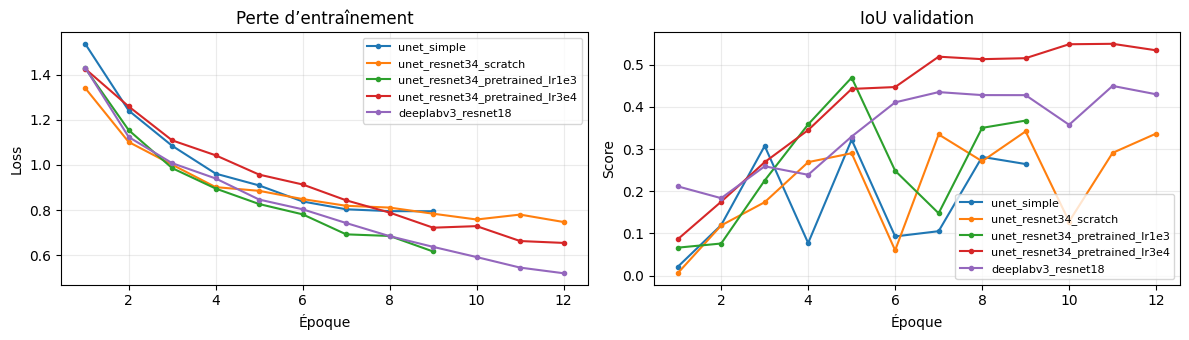

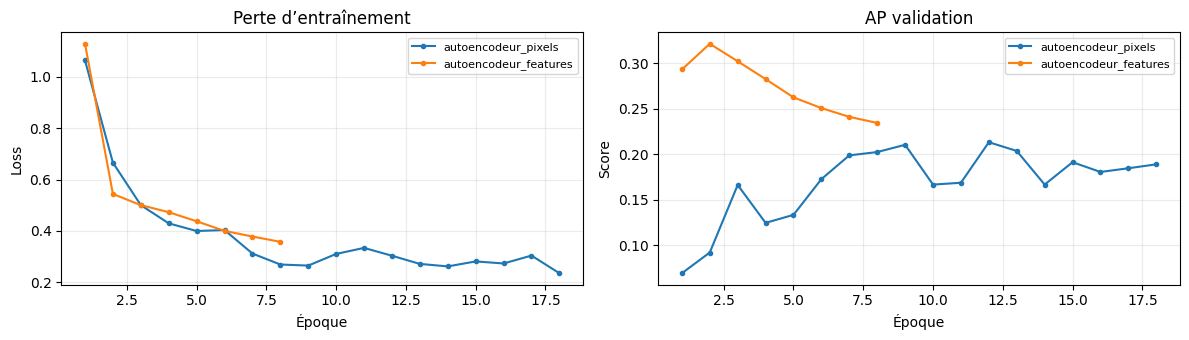

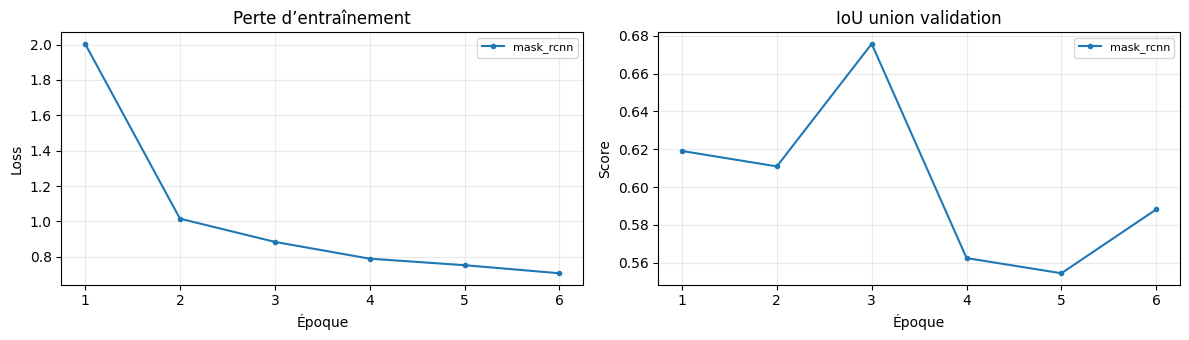

INTERPRÉTATION DES HISTORIQUES :
• unet_simple: meilleur score de validation = 0.322 à l’époque 5/9. La validation baisse malgré une perte train plus faible : surapprentissage possible.
• unet_resnet34_scratch: meilleur score de validation = 0.342 à l’époque 9/12. La meilleure époque précède la dernière ; le checkpoint optimal reste conservé.
• unet_resnet34_pretrained_lr1e3: meilleur score de validation = 0.469 à l’époque 5/9. La validation baisse malgré une perte train plus faible : surapprentissage possible.
• unet_resnet34_pretrained_lr3e4: meilleur score de validation = 0.550 à l’époque 11/12. La meilleure époque précède la dernière ; le checkpoint optimal reste conservé.
• deeplabv3_resnet18: meilleur score de validation = 0.450 à l’époque 11/12. La meilleure époque précède la dernière ; le checkpoint optimal reste conservé.
• autoencodeur_pixels: meilleur score de validation = 0.213 à l’époque 12/18. La meilleure époque précède la dernière ; le checkpoint optimal reste conservé.

In [ ]:
# Courbes issues des CSV existants : aucune réexécution des entraînements.
historiques = []
for nom, _, fichier in EXPERIMENTS:
    hist_path = OUT / f'{Path(fichier).stem}_history.csv'
    if hist_path.exists():
        h = pd.read_csv(hist_path)
        h['modèle'] = Path(fichier).stem
        h['validation'] = h['val_IoU']
        h['mesure'] = 'IoU validation'
        historiques.append(h[['epoch', 'train_loss', 'validation', 'modèle', 'mesure']])
for nom, _ in CONFIG_AE:
    hist_path = OUT / f'{nom}_history.csv'
    if hist_path.exists():
        h = pd.read_csv(hist_path)
        h['modèle'] = nom
        h['validation'] = h['val_AP']
        h['mesure'] = 'AP validation'
        historiques.append(h[['epoch', 'train_loss', 'validation', 'modèle', 'mesure']])
hist_path = OUT / 'mask_rcnn_history.csv'
if hist_path.exists():
    h = pd.read_csv(hist_path)
    h['modèle'] = 'mask_rcnn'
    h['validation'] = h['val_union_IoU']
    h['mesure'] = 'IoU union validation'
    historiques.append(h[['epoch', 'train_loss', 'validation', 'modèle', 'mesure']])

if not historiques:
    print('Aucun historique CSV disponible : entraîner ou restaurer les checkpoints et historiques.')
else:
    all_hist = pd.concat(historiques, ignore_index=True)
    for type_metrique, groupe in all_hist.groupby('mesure', sort=False):
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
        for nom, h in groupe.groupby('modèle', sort=False):
            ax[0].plot(h['epoch'], h['train_loss'], marker='.', label=nom)
            ax[1].plot(h['epoch'], h['validation'], marker='.', label=nom)
        ax[0].set(title='Perte d’entraînement', xlabel='Époque', ylabel='Loss')
        ax[1].set(title=type_metrique, xlabel='Époque', ylabel='Score')
        ax[0].legend(fontsize=8)
        ax[1].legend(fontsize=8)
        ax[0].grid(alpha=0.25); ax[1].grid(alpha=0.25)
        plt.tight_layout()
        fig.savefig(OUT / f"courbes_{type_metrique.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
        plt.show()

    print('INTERPRÉTATION DES HISTORIQUES :')
    for nom, h in all_hist.groupby('modèle', sort=False):
        h = h.sort_values('epoch').reset_index(drop=True)
        k = int(h['validation'].idxmax())
        meilleure_ep = int(h.loc[k, 'epoch'])
        meilleure_val = float(h.loc[k, 'validation'])
        commentaire = (f'{nom}: meilleur score de validation = {meilleure_val:.3f} '
                       f'à l’époque {meilleure_ep}/{int(h.epoch.max())}.')
        if len(h) >= 3 and k < len(h)-1:
            derniere_val = float(h['validation'].iloc[-1])
            if (meilleure_val - derniere_val) > 0.05 and h['train_loss'].iloc[-1] < h['train_loss'].iloc[k]:
                commentaire += ' La validation baisse malgré une perte train plus faible : surapprentissage possible.'
            else:
                commentaire += ' La meilleure époque précède la dernière ; le checkpoint optimal reste conservé.'
        elif k == len(h)-1:
            commentaire += ' La meilleure validation est atteinte à la dernière époque observée.'
        print('•', commentaire)

# Ablation : comparer sur validation, sans déduire de causalité sur le test.
if historiques:
    max_scores = all_hist.groupby('modèle')['validation'].max()
    scratch = 'unet_resnet34_scratch'
    pretrains = [x for x in max_scores.index if x.startswith('unet_resnet34_pretrained')]
    if scratch in max_scores and pretrains:
        meilleur_pretrain = max(pretrains, key=lambda x: max_scores[x])
        print(f"Ablation ResNet34 — meilleure IoU validation scratch : {max_scores[scratch]:.3f} ; "
              f"pré-entraîné : {max_scores[meilleur_pretrain]:.3f}. "
              "Ce résultat concerne ce découpage de validation uniquement.")

**Lecture des courbes.** Les modèles pré-entraînés peuvent converger plus rapidement que leurs équivalents initialisés au hasard : c’est l’hypothèse du *transfer learning* sur un petit dataset. Les fluctuations de validation ne prouvent pas à elles seules un surapprentissage, surtout avec **9 images de validation**. L’écart entre entraînement et validation doit être interprété avec prudence. **Les commentaires affichés ci-dessus sont calculés à partir des historiques du notebook, et non supposés à l’avance.**

La perte et les scores IoU/AP ne sont **pas dans les mêmes unités** ; ils sont donc tracés sur des axes distincts.

## 5. Évaluation finale sur test

Le **test n’intervient pas dans la sélection** des hyperparamètres, des checkpoints ou des seuils. Nous évaluons une seule fois chaque configuration retenue.

### 5.1. Segmentation sémantique

Nous gardons la meilleure expérience de chaque architecture selon **l’IoU de validation**, puis calculons les métriques **IoU, Dice, précision et rappel** sur les **9 images de test**.

In [ ]:
selected=(valid_results.sort_values('val_IoU',ascending=False)
          .drop_duplicates('model').reset_index(drop=True))
semantic_results=[]
for _,r in selected.iterrows():
    model=reload_semantic(r['model'],Path(r['checkpoint']))
    scores=semantic_scores(model,test_loader)
    semantic_results.append({'Modèle':r['model'],'LR':r['lr'],**scores})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
semantic_table=pd.DataFrame(semantic_results).sort_values('IoU',ascending=False)
semantic_table.to_csv(OUT/'test_semantic.csv',index=False)
display(semantic_table.round(4))

,Modèle,LR,IoU,Dice,Precision,Recall
0,unet_resnet34_pretrained,0.0003,0.5731,0.7045,0.6072,0.9403
1,deeplabv3_resnet18,0.0003,0.5193,0.6503,0.6000,0.8361
2,unet_resnet34_scratch,0.0010,0.3251,0.4272,0.3927,0.7710
3,unet_simple,0.0010,0.2915,0.4016,0.3864,0.8710


### 5.2. Autoencodeurs : AP et seuil sélectionné sur validation

1. Calculer la **carte d’erreur continue** sur la validation.
2. Choisir le seuil maximisant le **F1 de validation** (sans regarder le test).
3. Appliquer ce seuil au **test**, puis calculer **AP, IoU, Dice, précision et rappel**.

**AP** mesure le classement des pixels suspects sans seuil ; **IoU et Dice** mesurent la qualité de la segmentation après binarisation. Les deux familles de métriques ne sont pas interchangeables.

In [ ]:
def seuil_optimal_validation(scores, y_true):
    # Grille de quantiles : recherche légère, sans utiliser le test.
    candidats = np.unique(np.quantile(scores, np.linspace(0.50, 0.999, 120)))
    meilleur_seuil, meilleur_f1 = float(candidats[0]), -1.0
    vrais = y_true.astype(bool)
    for seuil in candidats:
        pred = scores >= seuil
        tp = np.logical_and(pred, vrais).sum()
        fp = np.logical_and(pred, ~vrais).sum()
        fn = np.logical_and(~pred, vrais).sum()
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        if f1 > meilleur_f1:
            meilleur_seuil, meilleur_f1 = float(seuil), float(f1)
    return meilleur_seuil, meilleur_f1


def metriques_binaires(scores, vrais, seuil):
    # Même protocole que semantic_scores : métriques par image, puis moyenne.
    pred = (scores >= seuil).reshape(-1, IMG_SIZE[1], IMG_SIZE[0])
    label = vrais.astype(bool).reshape(-1, IMG_SIZE[1], IMG_SIZE[0])
    tp = np.logical_and(pred, label).sum(axis=(1, 2))
    fp = np.logical_and(pred, ~label).sum(axis=(1, 2))
    fn = np.logical_and(~pred, label).sum(axis=(1, 2))
    return {'IoU': np.mean((tp + 1e-7) / (tp + fp + fn + 1e-7)),
            'Dice': np.mean((2*tp + 1e-7) / (2*tp + fp + fn + 1e-7)),
            'Precision': np.mean((tp + 1e-7) / (tp + fp + 1e-7)),
            'Recall': np.mean((tp + 1e-7) / (tp + fn + 1e-7))}

resultats_ae = []
for nom, _ in CONFIG_AE:
    modele = charger_autoencodeur(nom)
    val_scores, val_masks = cartes_et_masques_ae(modele, val_loader)
    seuil, f1_val = seuil_optimal_validation(val_scores, val_masks)
    test_scores, test_masks = cartes_et_masques_ae(modele, test_loader)
    resultat = {'Modèle': nom, 'AP_validation': average_precision_score(val_masks, val_scores),
                'Seuil_validation': seuil, 'F1_validation': f1_val,
                'AP_test': average_precision_score(test_masks, test_scores),
                **metriques_binaires(test_scores, test_masks, seuil)}
    resultats_ae.append(resultat)
    del modele
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

table_autoencodeurs = pd.DataFrame(resultats_ae).sort_values('AP_validation', ascending=False)
table_autoencodeurs.to_csv(OUT / 'test_autoencodeurs.csv', index=False)
display(table_autoencodeurs.round(4))

,Modèle,AP_validation,Seuil_validation,F1_validation,AP_test,IoU,Dice,Precision,Recall
1,autoencodeur_features,0.3213,0.7275,0.4228,0.3116,0.2420,0.3632,0.3057,0.7583
0,autoencodeur_pixels,0.2131,0.4608,0.3120,0.1853,0.1185,0.1976,0.1494,0.5753


**Interprétation des autoencodeurs.** L’autoencodeur de pixels peut réagir fortement aux variations de couleur ou de luminosité, même sur des zones normales. La reconstruction de *features* vise à réduire cette sensibilité, mais sa supériorité doit être **démontrée sur le test**. Un score de reconstruction élevé **suggère** une anomalie ; il ne prouve pas la présence d’un obstacle.

### 5.3. Mask R-CNN : segmentation et détection d’instances

L’**IoU d’union** vérifie le recouvrement de tous les obstacles réunis. La précision, le rappel et le F1 d’instances sont calculés par appariement des masques, avec **IoU ≥ 0,5** et score de confiance **≥ 0,5**.

Les scores d’instances sur **8 images de test** ne doivent **pas être directement comparés** aux IoU sémantiques calculées sur 9 images.

In [ ]:
# Évaluation finale uniquement : le modèle a été entraîné dans la section 3.3.
mask_model = make_maskrcnn().to(DEVICE)
mask_model.load_state_dict(torch.load(OUT/'mask_rcnn.pt', map_location=DEVICE, weights_only=True)['state_dict'])
mask_model.eval()
print('IoU union — test :', round(maskrcnn_union_iou(mask_model, itest), 4))

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 156MB/s]


IoU union — test : 0.6355


In [ ]:
@torch.no_grad()
def instance_detection_scores(model,loader,score_thr=0.5,iou_thr=0.5):
    model.eval(); TP=FP=FN=0
    for imgs,targets in loader:
        outs=model([im.to(DEVICE) for im in imgs])
        for out,t in zip(outs,targets):
            keep=(out['scores'].cpu().numpy()>=score_thr)
            pm=(out['masks'].cpu().numpy()[keep,0]>0.5)
            scores=out['scores'].cpu().numpy()[keep]
            true=t['masks'].cpu().numpy().astype(bool)
            matched=set()
            for j in np.argsort(-scores):
                if not len(true): FP+=1;continue
                ints=np.logical_and(true,pm[j]).sum(axis=(1,2))
                unions=np.logical_or(true,pm[j]).sum(axis=(1,2))
                ious=ints/np.maximum(unions,1)
                for k in matched: ious[k]=-1
                k=int(np.argmax(ious))
                if ious[k]>=iou_thr:
                    TP+=1; matched.add(k)
                else: FP+=1
            FN+=len(true)-len(matched)
    prec=TP/max(TP+FP,1);rec=TP/max(TP+FN,1)
    return {'TP':TP,'FP':FP,'FN':FN,'Precision':prec,'Recall':rec,
            'F1':2*prec*rec/max(prec+rec,1e-8)}

instance_scores=instance_detection_scores(mask_model,itest)
display(pd.DataFrame([instance_scores]).round(4))
pd.DataFrame([instance_scores]).to_csv(OUT/'test_mask_rcnn_instances.csv',index=False)

,TP,FP,FN,Precision,Recall,F1
0,13,14,11,0.4815,0.5417,0.5098


## 6. Visualisation des prédictions

Comparer **l’image**, **l’annotation réelle** et la **prédiction** sur le test pour comprendre les faux positifs, les obstacles manqués et les contours imprécis. Ces exemples illustrent les résultats sans remplacer les métriques quantitatives.

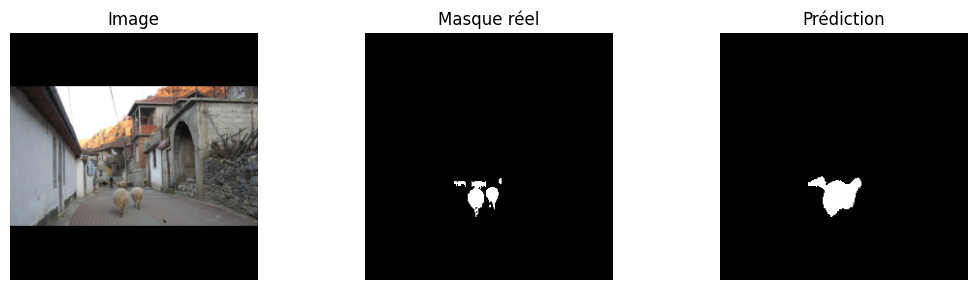

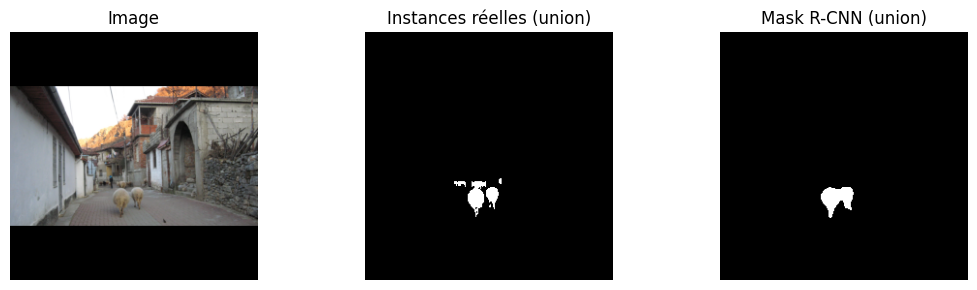

In [ ]:
best_row=semantic_table.iloc[0]
best_model=reload_semantic(best_row['Modèle'],selected.set_index('model').loc[best_row['Modèle'],'checkpoint'])
x,y=SemanticDataset(test_df)[0]
with torch.no_grad():
    p=(torch.sigmoid(best_model(x[None].to(DEVICE)))[0,0].cpu().numpy()>0.5)
raw=np.clip(x.numpy().transpose(1,2,0)*STD+MEAN,0,1)
fig,ax=plt.subplots(1,3,figsize=(11,3))
for a,im,title in zip(ax,[raw,y[0].numpy(),p],['Image','Masque réel','Prédiction']):
    a.imshow(im,cmap=None if title=='Image' else 'gray');a.set_title(title);a.axis('off')
plt.tight_layout();plt.show()

i,t=InstanceDataset(test_df)[0]
with torch.no_grad(): pred=mask_model([i.to(DEVICE)])[0]
pred_masks=pred['masks'].cpu().numpy()[pred['scores'].cpu().numpy()>=0.5,0]>0.5
union=pred_masks.any(axis=0) if len(pred_masks) else np.zeros((256,256),bool)
fig,ax=plt.subplots(1,3,figsize=(11,3))
for a,im,title in zip(ax,[i.numpy().transpose(1,2,0),t['masks'].bool().any(dim=0).numpy(),union],
                      ['Image','Instances réelles (union)','Mask R-CNN (union)']):
    a.imshow(im,cmap=None if title=='Image' else 'gray');a.set_title(title);a.axis('off')
plt.tight_layout();plt.show()

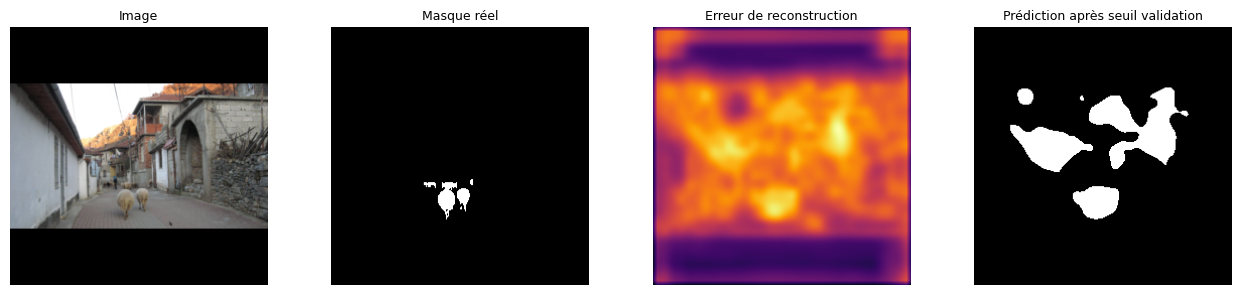

In [ ]:
# Exemple de carte d'anomalie pour l'autoencodeur ayant la meilleure AP de validation.
if 'table_autoencodeurs' in globals() and not table_autoencodeurs.empty:
    nom = table_autoencodeurs.iloc[0]['Modèle']
    seuil = float(table_autoencodeurs.iloc[0]['Seuil_validation'])
    ae = charger_autoencodeur(nom)
    image, masque = SemanticDataset(test_df)[0]
    with torch.no_grad():
        carte = ae.carte_anomalie(image[None].to(DEVICE))[0, 0].cpu().numpy()
    rgb = np.clip(image.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)
    fig, ax = plt.subplots(1, 4, figsize=(13, 3))
    for a, img, titre in zip(ax, [rgb, masque[0].numpy(), carte, carte >= seuil],
                             ['Image', 'Masque réel', 'Erreur de reconstruction', 'Prédiction après seuil validation']):
        a.imshow(img, cmap=None if titre=='Image' else ('inferno' if titre=='Erreur de reconstruction' else 'gray'))
        a.set_title(titre, fontsize=9); a.axis('off')
    plt.tight_layout(); plt.show()
    del ae
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 7. Bilan et limites

- **Segmentation sémantique :** comparaison de U-Net, U-Net ResNet34 avec et sans ImageNet et DeepLabV3, sur le **même test de 9 images**. La comparaison scratch/pré-entraîné teste l’apport du *transfer learning*.
- **Autoencodeurs :** approches complémentaires de reconstruction guidée, avec **AP et seuil choisis sur validation**. Leur performance dépend des cartes d’erreur réellement produites.
- **Segmentation d’instances :** Mask R-CNN identifie les objets individuellement sur un **sous-ensemble de 8 images de test**, avec des métriques dédiées.
- **Hyperparamètres :** comparaison limitée de deux LR pour U-Net ResNet34 pré-entraîné, arrêt anticipé et sauvegarde du meilleur checkpoint. **Une recherche exhaustive n’a pas été menée.**
- **Limites :** 60 images seulement ; validation/test très petits ; résultats sensibles au découpage et aux scènes similaires ; modèles de familles différentes non comparables par une seule métrique.

**CRISP-DM — suite :** analyser les erreurs, comparer les compromis précision/rappel et discuter la généralisation. Les tableaux et historiques générés sont sauvegardés dans `RoadAnomaly_final_models`.